## Yerel Spark ortamı kontrolü

Spark oturumunu iki yerel iş parçacığıyla başlatıyorum. Küçük bir örnek veri üzerinde filtreleme ve sayım yaparak Notebook ortamının Spark sorgusu çalıştırabildiğini doğruluyorum.

In [2]:
import sys

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("MovieLensAtlas")
    .master("local[2]")
    .getOrCreate()
)

print("Python yolu:", sys.executable)
print("Spark sürümü:", spark.version)
print("Çalışma modu:", spark.sparkContext.master)

numbers = spark.range(5)
filtered = numbers.filter(numbers["id"] >= 2)
print("Filtre sonrası satır sayısı:", filtered.count())

Python yolu: c:\Users\busra\Projects\MovieLensAtlas\.venv\Scripts\python.exe
Spark sürümü: 4.1.1
Çalışma modu: local[2]
Filtre sonrası satır sayısı: 3


## MovieLens puan dosyasına ilk bakış

`ratings.dat` dosyasını Spark ile metin olarak okuyorum. İlk üç kaydı
inceleyerek her satırın `::` ile ayrılmış bir puan kaydı olduğunu kontrol ediyorum.

In [3]:
from pathlib import Path

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

ratings_path = project_root / "data" / "ratings.dat"

if not ratings_path.is_file():
    raise FileNotFoundError(f"Puan dosyası bulunamadı: {ratings_path}")

print("Dosya yolu:", ratings_path)

ratings_raw = spark.read.text(ratings_path.as_uri())
ratings_raw.printSchema()
ratings_raw.show(3, truncate=False)

Dosya yolu: c:\Users\busra\Projects\MovieLensAtlas\data\ratings.dat
root
 |-- value: string (nullable = true)

+---------------------+
|value                |
+---------------------+
|1::1193::5::978300760|
|1::661::3::978302109 |
|1::914::3::978301968 |
+---------------------+
only showing top 3 rows


## Puan kayıtlarının ayrıştırılması

Ham satırları `::` ayracına göre dört alana bölüyorum. Kullanıcı kimliğini,
film kimliğini ve puanı tam sayıya, zaman damgasını uzun tam sayıya
dönüştürüyorum. Alan sayısı ve tür dönüşümü hatalarını sayarak ham
kayıtların kaçının bu şemaya uyduğunu kontrol ediyorum.

In [4]:
from pyspark.sql import functions as F

ratings_parts = ratings_raw.withColumn("parts", F.split("value", "::"))

ratings_parsed = ratings_parts.select(
    F.size("parts").alias("field_count"),
    F.get("parts", 0).try_cast("int").alias("UserID"),
    F.get("parts", 1).try_cast("int").alias("MovieID"),
    F.get("parts", 2).try_cast("int").alias("Rating"),
    F.get("parts", 3).try_cast("long").alias("Timestamp"),
)

ratings = ratings_parsed.drop("field_count")
ratings.printSchema()
ratings.show(3, truncate=False)

parse_error = (
    (F.col("field_count") != 4)
    | F.col("UserID").isNull()
    | F.col("MovieID").isNull()
    | F.col("Rating").isNull()
    | F.col("Timestamp").isNull()
)

ratings_parsed.agg(
    F.count("*").alias("total_rows"),
    F.count(F.when(parse_error, 1)).alias("parse_error_rows"),
).show()

root
 |-- UserID: integer (nullable = true)
 |-- MovieID: integer (nullable = true)
 |-- Rating: integer (nullable = true)
 |-- Timestamp: long (nullable = true)

+------+-------+------+---------+
|UserID|MovieID|Rating|Timestamp|
+------+-------+------+---------+
|1     |1193   |5     |978300760|
|1     |661    |3     |978302109|
|1     |914    |3     |978301968|
+------+-------+------+---------+
only showing top 3 rows
+----------+----------------+
|total_rows|parse_error_rows|
+----------+----------------+
|   1000209|               0|
+----------+----------------+



## Film dosyasının karakter kodlaması

Film adlarındaki özel karakterlerin doğru okunması için `movies.dat`
dosyasını UTF-8 ile çözümlemeyi deniyorum. Sonucu Spark okuma ayarını
seçmek için kullanıyorum.

In [5]:
movies_path = project_root / "data" / "movies.dat"
movie_bytes = movies_path.read_bytes()

try:
    movie_text = movie_bytes.decode("utf-8")
    print("UTF-8 çözümleme başarılı.")
except UnicodeDecodeError as error:
    print("UTF-8 çözümleme başarısız.")
    print("İlk sorunlu bayt konumu:", error.start)
    print("Çözümleme hatası:", error.reason)
else:
    for line in movie_text.splitlines():
        if not line.isascii():
            print("ASCII dışı karakter içeren örnek:", line)
            break

UTF-8 çözümleme başarısız.
İlk sorunlu bayt konumu: 3114
Çözümleme hatası: invalid continuation byte


## Film başlıkları için kodlama kontrolü

UTF-8 çözümlemesinin takıldığı satırı iki aday kodlamayla okuyorum.
Dosyada bu iki kodlamanın farklı yorumladığı baytlar var mı diye kontrol
ederek Spark'ta kullanacağım kodlamayı belirliyorum.

In [6]:
position = 3114
line_start = movie_bytes.rfind(b"\n", 0, position) + 1
line_end = movie_bytes.find(b"\n", position)
raw_line = movie_bytes[line_start:line_end if line_end != -1 else len(movie_bytes)]

print("Sorunlu bayt:", hex(movie_bytes[position]))
print("Latin-1 örneği:", raw_line.decode("latin-1").rstrip())
print("Windows-1252 örneği:", raw_line.decode("cp1252", errors="replace").rstrip())

different_bytes = sorted({byte for byte in movie_bytes if 0x80 <= byte <= 0x9F})
print("İki kodlamanın ayrıştığı baytlar:", [hex(byte) for byte in different_bytes])

Sorunlu bayt: 0xe9
Latin-1 örneği: 73::Misérables, Les (1995)::Drama|Musical
Windows-1252 örneği: 73::Misérables, Les (1995)::Drama|Musical
İki kodlamanın ayrıştığı baytlar: []


## Film tablosunun okunması

`movies.dat` dosyasını ISO-8859-1 kodlaması ve `::` alan ayracıyla
okuyorum. Sütun adlarını ve tiplerini açıkça tanımlıyorum.
Satır sayısını, örnek kayıtları ve aksanlı bir film başlığını kontrol ediyorum.

In [7]:
first_line_break = movie_bytes.index(b"\n")
line_sep = "\r\n" if movie_bytes[first_line_break - 1] == 13 else "\n"

movies = (
    spark.read
    .schema("MovieID INT, Title STRING, Genres STRING")
    .option("header", False)
    .option("sep", "::")
    .option("encoding", "ISO-8859-1")
    .option("lineSep", line_sep)
    .option("quote", "")
    .option("mode", "FAILFAST")
    .csv(movies_path.as_uri())
)

movies.printSchema()
movies.show(3, truncate=False)
movies.where("MovieID = 73").show(truncate=False)

print("Ham dosyadaki satır sayısı:", len(movie_bytes.splitlines()))
print("Spark film satırı sayısı:", movies.count())

root
 |-- MovieID: integer (nullable = true)
 |-- Title: string (nullable = true)
 |-- Genres: string (nullable = true)

+-------+-----------------------+----------------------------+
|MovieID|Title                  |Genres                      |
+-------+-----------------------+----------------------------+
|1      |Toy Story (1995)       |Animation|Children's|Comedy |
|2      |Jumanji (1995)         |Adventure|Children's|Fantasy|
|3      |Grumpier Old Men (1995)|Comedy|Romance              |
+-------+-----------------------+----------------------------+
only showing top 3 rows
+-------+----------------------+-------------+
|MovieID|Title                 |Genres       |
+-------+----------------------+-------------+
|73     |Misérables, Les (1995)|Drama|Musical|
+-------+----------------------+-------------+

Ham dosyadaki satır sayısı: 3883
Spark film satırı sayısı: 3883


## Kullanıcı tablosunun okunması

Kullanıcı kayıtlarını `::` ayracına göre beş alana bölüyorum.
Yaş grubunu ve meslek kodunu tam sayı, posta kodunu metin olarak
saklıyorum. Satır sayısını ve ayrıştırma hatalarını kontrol ediyorum.

In [8]:
users_path = project_root / "data" / "users.dat"

users_raw = spark.read.text(users_path.as_uri())
users_parts = users_raw.withColumn("parts", F.split("value", "::"))

users_parsed = users_parts.select(
    F.size("parts").alias("field_count"),
    F.get("parts", 0).try_cast("int").alias("UserID"),
    F.get("parts", 1).alias("Gender"),
    F.get("parts", 2).try_cast("int").alias("Age"),
    F.get("parts", 3).try_cast("int").alias("Occupation"),
    F.get("parts", 4).alias("ZipCode"),
)

users = users_parsed.drop("field_count")
users.printSchema()
users.show(3, truncate=False)

user_parse_error = (
    (F.col("field_count") != 5)
    | F.col("UserID").isNull()
    | F.col("Age").isNull()
    | F.col("Occupation").isNull()
)

users_parsed.agg(
    F.count("*").alias("total_rows"),
    F.count(F.when(user_parse_error, 1)).alias("parse_error_rows"),
).show()

root
 |-- UserID: integer (nullable = true)
 |-- Gender: string (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Occupation: integer (nullable = true)
 |-- ZipCode: string (nullable = true)

+------+------+---+----------+-------+
|UserID|Gender|Age|Occupation|ZipCode|
+------+------+---+----------+-------+
|1     |F     |1  |10        |48067  |
|2     |M     |56 |16        |70072  |
|3     |M     |25 |15        |55117  |
+------+------+---+----------+-------+
only showing top 3 rows
+----------+----------------+
|total_rows|parse_error_rows|
+----------+----------------+
|      6040|               0|
+----------+----------------+



## Puan kayıtlarında veri kalitesi

Puanların 1–5 aralığında olduğunu ve zaman damgalarının dolu ve pozitif
olduğunu kontrol ediyorum. En erken ve en geç puanlama zamanını UTC
olarak gösteriyorum. Bu aşamada kayıtları değiştirmiyorum.

In [9]:
spark.conf.set("spark.sql.session.timeZone", "UTC")

invalid_rating = F.col("Rating").isNull() | ~F.col("Rating").between(1, 5)
invalid_timestamp = F.col("Timestamp").isNull() | (F.col("Timestamp") <= 0)

ratings_quality = ratings.agg(
    F.count("*").alias("total_rows"),
    F.min("Rating").alias("min_rating"),
    F.max("Rating").alias("max_rating"),
    F.count(F.when(invalid_rating, 1)).alias("invalid_rating_rows"),
    F.count(F.when(invalid_timestamp, 1)).alias("invalid_timestamp_rows"),
    F.timestamp_seconds(F.min("Timestamp")).alias("first_rating_utc"),
    F.timestamp_seconds(F.max("Timestamp")).alias("last_rating_utc"),
)

ratings_quality.show(truncate=False, vertical=True)

-RECORD 0-------------------------------------
 total_rows             | 1000209             
 min_rating             | 1                   
 max_rating             | 5                   
 invalid_rating_rows    | 0                   
 invalid_timestamp_rows | 0                   
 first_rating_utc       | 2000-04-25 23:05:32 
 last_rating_utc        | 2003-02-28 17:49:50 



## Puan kayıtlarında tekrar kontrolü

Dört alanı aynı olan kayıtları ve aynı kullanıcı–film çiftine ait
birden fazla kaydı ayrı ayrı sayıyorum. Her kontrol için tekrar
içeren grup sayısını ve her grupta bir kayıt kalsaydı kaç satırın
fazla olacağını gösteriyorum. Bu aşamada kayıtları değiştirmiyorum.

In [10]:
exact_duplicates = (
    ratings.groupBy("UserID", "MovieID", "Rating", "Timestamp")
    .count()
    .where(F.col("count") > 1)
)

repeated_pairs = (
    ratings.groupBy("UserID", "MovieID")
    .count()
    .where(F.col("count") > 1)
)

for label, groups in [
    ("Tam satır tekrarları", exact_duplicates),
    ("Kullanıcı–film çifti tekrarları", repeated_pairs),
]:
    print(label)
    groups.agg(
        F.count("*").alias("duplicate_groups"),
        F.coalesce(F.sum(F.col("count") - 1), F.lit(0)).alias("extra_rows"),
    ).show()

Tam satır tekrarları
+----------------+----------+
|duplicate_groups|extra_rows|
+----------------+----------+
|               0|         0|
+----------------+----------+

Kullanıcı–film çifti tekrarları
+----------------+----------+
|duplicate_groups|extra_rows|
+----------------+----------+
|               0|         0|
+----------------+----------+



## Film ve kullanıcı anahtarlarının kontrolü

Film tablosunda `MovieID`, kullanıcı tablosunda `UserID` alanını kontrol
ediyorum. Toplam satır sayısını, boş kimlik sayısını ve farklı kimlik
sayısını karşılaştırıyorum. Böylece bir kimliğin birden çok satıra
karşılık gelip gelmediğini görüyorum.

In [11]:
for table_name, table, key in [
    ("Film tablosu", movies, "MovieID"),
    ("Kullanıcı tablosu", users, "UserID"),
]:
    print(table_name)

    table.agg(
        F.count("*").alias("total_rows"),
        F.count(F.when(F.col(key).isNull(), 1)).alias("null_keys"),
        F.countDistinct(key).alias("distinct_keys"),
    ).show()

Film tablosu
+----------+---------+-------------+
|total_rows|null_keys|distinct_keys|
+----------+---------+-------------+
|      3883|        0|         3883|
+----------+---------+-------------+

Kullanıcı tablosu
+----------+---------+-------------+
|total_rows|null_keys|distinct_keys|
+----------+---------+-------------+
|      6040|        0|         6040|
+----------+---------+-------------+



## Puan kayıtlarında anahtar eşleşmesi

Her puan kaydındaki film ve kullanıcı kimliğini ilgili tabloda arıyorum.
Karşılığı bulunmayan puan satırlarını iki ayrı sayaçla gösteriyorum.
Bu kontrol sırasında puan tablosunu değiştirmiyorum.

In [12]:
ratings_without_movie = ratings.join(
    movies.select("MovieID"), on="MovieID", how="left_anti"
)

ratings_without_user = ratings.join(
    users.select("UserID"), on="UserID", how="left_anti"
)

print("Film eşleşmesi olmayan puan satırları:", ratings_without_movie.count())
print("Kullanıcı eşleşmesi olmayan puan satırları:", ratings_without_user.count())

Film eşleşmesi olmayan puan satırları: 0
Kullanıcı eşleşmesi olmayan puan satırları: 0


## Film ve kullanıcı alanlarının kalite kontrolü

Film adı ve türü boş olan kayıtları sayıyorum. İsteğe bağlı yaş analizi
için kullanıcıların yaş grubu kodlarını MovieLens 1M’deki geçerli
kodlarla karşılaştırıyorum. Bu adımda kayıtları değiştirmiyorum.

In [13]:
blank_title = F.col("Title").isNull() | (F.trim(F.col("Title")) == "")
blank_genres = F.col("Genres").isNull() | (F.trim(F.col("Genres")) == "")

valid_age_codes = [1, 18, 25, 35, 45, 50, 56]
invalid_age = F.col("Age").isNull() | ~F.col("Age").isin(valid_age_codes)

print("Film alanları")
movies.agg(
    F.count(F.when(blank_title, 1)).alias("blank_titles"),
    F.count(F.when(blank_genres, 1)).alias("blank_genres"),
).show()

print("Kullanıcı yaş kodları")
users.agg(
    F.count(F.when(invalid_age, 1)).alias("invalid_age_codes"),
).show()

Film alanları
+------------+------------+
|blank_titles|blank_genres|
+------------+------------+
|           0|           0|
+------------+------------+

Kullanıcı yaş kodları
+-----------------+
|invalid_age_codes|
+-----------------+
|                0|
+-----------------+



## Veri kalitesi kontrollerinin sonucu

Puan kayıtlarında geçersiz puan, eksik veya pozitif olmayan zaman
damgası, tam satır tekrarı ve kullanıcı–film çifti tekrarı bulmadım.
Film ve kullanıcı kimlikleri dolu ve tekil. Her puan kaydı ilgili
film ve kullanıcıyla eşleşiyor. Film adı ve tür alanları dolu,
yaş grubu kodları geçerli.

Bu kontroller sonucunda hiçbir kayıt çıkarmadım. Okuma sonrasında
ve analiz öncesinde satır sayıları aynı kaldı.

| Tablo | Okuma sonrası | Analiz öncesi | Çıkarılan kayıt |
| --- | ---: | ---: | ---: |
| Puanlar | 1.000.209 | 1.000.209 | 0 |
| Filmler | 3.883 | 3.883 | 0 |
| Kullanıcılar | 6.040 | 6.040 | 0 |

## Genel puan dağılımı

Her yıldız değeri için kaç puan kaydı olduğunu Spark ile hesaplıyorum.
Her sayıyı toplam puan kaydına bölerek yüzdesini buluyorum. Bu tablo,
türlere göre puanları incelerken genel dağılımla karşılaştırma yapmamı
sağlayacak.

In [14]:
total_ratings = ratings.count()

rating_distribution = (
    ratings.groupBy("Rating")
    .agg(F.count("*").alias("rating_count"))
    .withColumn(
        "rating_pct",
        F.col("rating_count") * 100.0 / total_ratings,
    )
    .orderBy("Rating")
)

rating_distribution.show()

rating_distribution.agg(
    F.sum("rating_count").alias("total_count"),
    F.round(F.sum("rating_pct"), 2).alias("total_pct"),
).show()

+------+------------+------------------+
|Rating|rating_count|        rating_pct|
+------+------------+------------------+
|     1|       56174| 5.616226208722377|
|     2|      107557| 10.75345252842156|
|     3|      261197| 26.11424212339621|
|     4|      348971|34.889808030121706|
|     5|      226310| 22.62627110933815|
+------+------------+------------------+

+-----------+---------+
|total_count|total_pct|
+-----------+---------+
|    1000209|    100.0|
+-----------+---------+



### Yıldızlara göre puanların yüzdesi

Spark'ta hesapladığım beş satırlık özeti Pandas'a aktarıp
Matplotlib ile çiziyorum. Her sütun, bir yıldız değerinin
tüm puan kayıtları içindeki yüzdesini gösteriyor.

Matplotlib is building the font cache; this may take a moment.


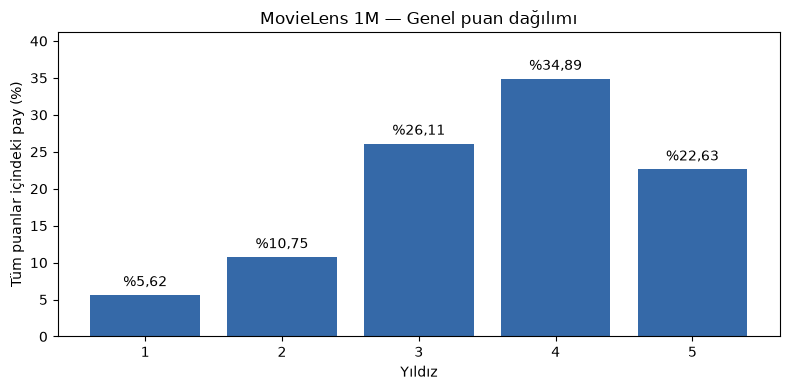

In [15]:
import matplotlib.pyplot as plt

rating_plot = rating_distribution.toPandas()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(rating_plot["Rating"], rating_plot["rating_pct"], color="#3569A8")

ax.set_title("MovieLens 1M — Genel puan dağılımı")
ax.set_xlabel("Yıldız")
ax.set_ylabel("Tüm puanlar içindeki pay (%)")
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_ylim(0, rating_plot["rating_pct"].max() * 1.18)
ax.bar_label(
    bars,
    labels=[f"%{pct:.2f}".replace(".", ",") for pct in rating_plot["rating_pct"]],
    padding=4,
)

fig.tight_layout()
plt.show()

### Genel puan dağılımının yorumu

MovieLens 1M’de en sık verilen puan 4 yıldızdır. 348.971 kayıtla
tüm puanların %34,89’unu oluşturur. 4 ve 5 yıldız birlikte tüm
puanların %57,52’sini oluşturur. Tür analizinde 4–5 yıldız oranlarını
bu veri seti geneliyle karşılaştıracağım.

## Puan ve film tablolarının birleştirilmesi

Puan kayıtlarına film adını ve türlerini eklemek için iki tabloyu
`MovieID` üzerinden birleştiriyorum. Birleştirmeden önceki ve sonraki
satır sayılarını karşılaştırarak her puan kaydının korunduğunu
kontrol ediyorum.

In [16]:
ratings_with_movies = ratings.join(
    movies.select("MovieID", "Title", "Genres"),
    on="MovieID",
    how="inner",
)

joined_rating_count = ratings_with_movies.count()

print("Birleştirme öncesi:", total_ratings)
print("Birleştirme sonrası:", joined_rating_count)
print("Satır farkı:", joined_rating_count - total_ratings)

ratings_with_movies.select(
    "UserID", "MovieID", "Rating", "Title", "Genres"
).show(5, truncate=False)

Birleştirme öncesi: 1000209
Birleştirme sonrası: 1000209
Satır farkı: 0
+------+-------+------+--------------------------------------+----------------------------+
|UserID|MovieID|Rating|Title                                 |Genres                      |
+------+-------+------+--------------------------------------+----------------------------+
|1     |1193   |5     |One Flew Over the Cuckoo's Nest (1975)|Drama                       |
|1     |661    |3     |James and the Giant Peach (1996)      |Animation|Children's|Musical|
|1     |914    |3     |My Fair Lady (1964)                   |Musical|Romance             |
|1     |3408   |4     |Erin Brockovich (2000)                |Drama                       |
|1     |2355   |5     |Bug's Life, A (1998)                  |Animation|Children's|Comedy |
+------+-------+------+--------------------------------------+----------------------------+
only showing top 5 rows


## Film türlerinin ayrı satırlara açılması

Tür etiketlerini `|` işaretinden ayırıp her puan–tür çifti için bir
satır oluşturuyorum. Açılan satır sayısını, açma öncesinde puan
kayıtlarına bağlı tür etiketi sayısıyla karşılaştırıyorum.

In [17]:
ratings_with_genre_lists = ratings_with_movies.withColumn(
    "GenreList",
    F.array_distinct(F.split("Genres", r"\|")),
)

ratings_by_genre = ratings_with_genre_lists.select(
    "UserID",
    "MovieID",
    "Rating",
    F.explode("GenreList").alias("Genre"),
)

expected_genre_rows = ratings_with_genre_lists.agg(
    F.sum(F.size("GenreList")).alias("expected_rows")
).first()["expected_rows"]

actual_genre_rows = ratings_by_genre.count()

print("Açma öncesi puan satırı:", joined_rating_count)
print("Beklenen puan–tür satırı:", expected_genre_rows)
print("Oluşan puan–tür satırı:", actual_genre_rows)
print("Beklenen ile oluşan arasındaki fark:", actual_genre_rows - expected_genre_rows)

ratings_by_genre.where(
    (F.col("UserID") == 1) & (F.col("MovieID") == 661)
).orderBy("Genre").show(truncate=False)

Açma öncesi puan satırı: 1000209
Beklenen puan–tür satırı: 2101815
Oluşan puan–tür satırı: 2101815
Beklenen ile oluşan arasındaki fark: 0
+------+-------+------+----------+
|UserID|MovieID|Rating|Genre     |
+------+-------+------+----------+
|1     |661    |3     |Animation |
|1     |661    |3     |Children's|
|1     |661    |3     |Musical   |
+------+-------+------+----------+



## Türlere göre puanlama özeti

Her tür için puan kaydı sayısını, ortalama puanı ve 4–5 yıldız alan
kayıtların yüzdesini hesaplıyorum. Yüksek puan yüzdesinin paydası,
ilgili türün tüm puan kayıtlarıdır. Tür sayımlarının toplamını
türleri açtıktan sonra elde ettiğim satır sayısıyla karşılaştırıyorum.

In [18]:
genre_summary = (
    ratings_by_genre.groupBy("Genre")
    .agg(
        F.count("*").alias("rating_count"),
        F.avg("Rating").alias("avg_rating"),
        F.count(F.when(F.col("Rating") >= 4, 1)).alias("high_rating_count"),
    )
    .withColumn(
        "high_rating_pct",
        100.0 * F.col("high_rating_count") / F.col("rating_count"),
    )
    .orderBy(F.desc("rating_count"), F.asc("Genre"))
)

genre_summary.select(
    "Genre",
    "rating_count",
    F.round("avg_rating", 2).alias("avg_rating"),
    "high_rating_count",
    F.round("high_rating_pct", 2).alias("high_rating_pct"),
).show(truncate=False)

summary_genre_rows = genre_summary.agg(
    F.sum("rating_count").alias("total")
).first()["total"]

print("Tür özetindeki toplam:", summary_genre_rows)
print("Açılan satır sayısına göre fark:", summary_genre_rows - actual_genre_rows)

+-----------+------------+----------+-----------------+---------------+
|Genre      |rating_count|avg_rating|high_rating_count|high_rating_pct|
+-----------+------------+----------+-----------------+---------------+
|Comedy     |356580      |3.52      |196945           |55.23          |
|Drama      |354529      |3.77      |228440           |64.43          |
|Action     |257457      |3.49      |138766           |53.9           |
|Thriller   |189680      |3.57      |108216           |57.05          |
|Sci-Fi     |157294      |3.47      |83197            |52.89          |
|Romance    |147523      |3.61      |85499            |57.96          |
|Adventure  |133953      |3.48      |70951            |52.97          |
|Crime      |79541       |3.71      |49347            |62.04          |
|Horror     |76386       |3.22      |34088            |44.63          |
|Children's |72186       |3.42      |37278            |51.64          |
|War        |68527       |3.89      |47542            |69.38    

### Türlere göre puan sayısı ve yüksek puan oranı

Solda her türün puan kaydı sayısını, sağda o türdeki puanların
yüzde kaçının 4 veya 5 yıldız olduğunu gösteriyorum. Kesikli çizgi,
türler açılmadan önce tüm puanlardan hesapladığım genel oranı gösteriyor.
Bir film birden fazla türe ait olabildiği için aynı puan birden çok
türün hesabına girebilir.

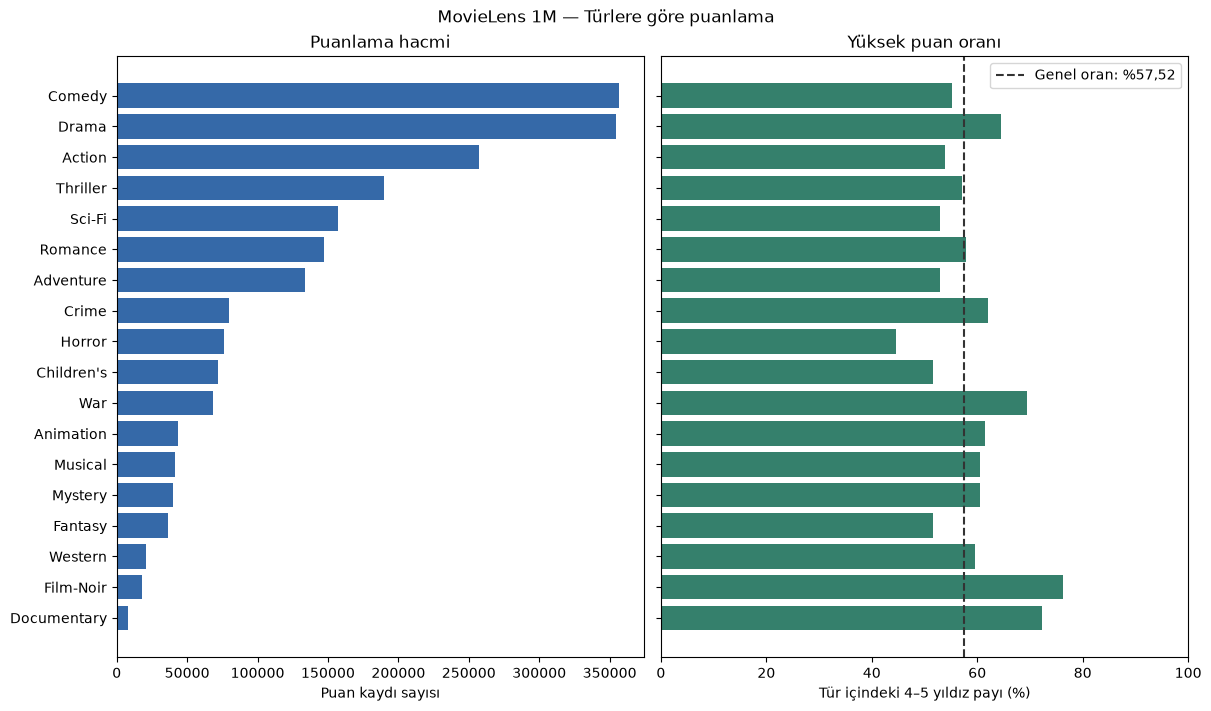

In [19]:
genre_plot = genre_summary.select(
    "Genre", "rating_count", "high_rating_pct"
).toPandas()

overall_high_pct = rating_plot.loc[
    rating_plot["Rating"].isin([4, 5]), "rating_pct"
].sum()

fig, (ax_count, ax_pct) = plt.subplots(
    1, 2, figsize=(12, 7), sharey=True, layout="constrained"
)

ax_count.barh(genre_plot["Genre"], genre_plot["rating_count"], color="#3569A8")
ax_count.invert_yaxis()
ax_count.set_title("Puanlama hacmi")
ax_count.set_xlabel("Puan kaydı sayısı")

ax_pct.barh(genre_plot["Genre"], genre_plot["high_rating_pct"], color="#35806C")
ax_pct.axvline(
    overall_high_pct,
    color="#333333",
    linestyle="--",
    label=f"Genel oran: %{overall_high_pct:.2f}".replace(".", ","),
)
ax_pct.set_xlim(0, 100)
ax_pct.set_title("Yüksek puan oranı")
ax_pct.set_xlabel("Tür içindeki 4–5 yıldız payı (%)")
ax_pct.legend(loc="upper right")

fig.suptitle("MovieLens 1M — Türlere göre puanlama")
plt.show()

### Türlere göre puanlamanın yorumu

Comedy ve Drama, en çok puan kaydı olan iki türdür. Puan sayıları
birbirine yakın olsa da 4–5 yıldız oranı Drama'da %64,43,
Comedy'de %55,23'tür. Aradaki fark 9,20 yüzde puanıdır.

Film-Noir, 18.261 puan kaydında %76,35 ile en yüksek 4–5 yıldız
oranına ve 4,08 ile en yüksek ortalama puana sahiptir. Bu oranlar
MovieLens kullanıcılarının verdiği puanları gösterir. Bir film
birden çok türe ait olduğunda puanı her türün hesabına girer.